QA 이미지 수: 28


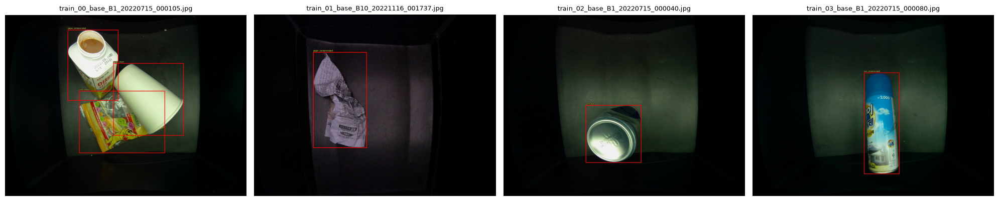

Enter → 다음 4장 / 중단하려면 Ctrl+C 


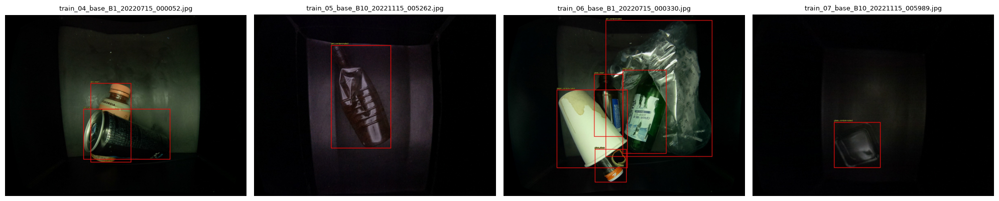

Enter → 다음 4장 / 중단하려면 Ctrl+C 


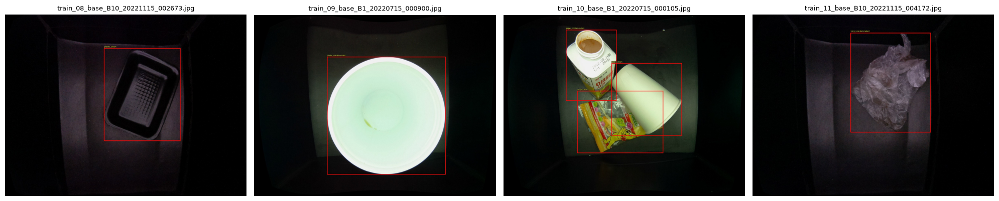

Enter → 다음 4장 / 중단하려면 Ctrl+C 


/tmp/ipykernel_13304/1526857057.py:30: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_13304/1526857057.py:30: UserWarning: Glyph 45236 (\N{HANGUL SYLLABLE NAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_13304/1526857057.py:30: UserWarning: Glyph 54805 (\N{HANGUL SYLLABLE HYEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_13304/1526857057.py:30: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_13304/1526857057.py:30: UserWarning: Glyph 47448 (\N{HANGUL SYLLABLE RYU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_13304/1526857057.py:30: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/jupyter-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL})

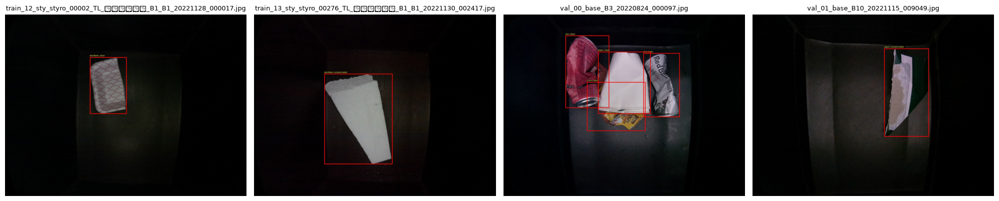

Enter → 다음 4장 / 중단하려면 Ctrl+C 


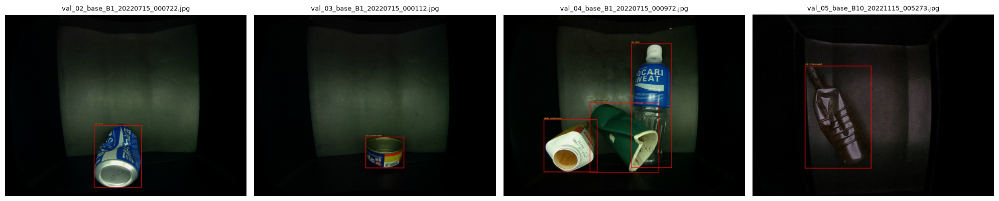

KeyboardInterrupt: Interrupted by user

In [1]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

qa_dir = Path("/data/recycle_dataset/model_a_stage1_14class_27500_v1/qa_preview")

images = sorted([
    p for p in qa_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
])

print("QA 이미지 수:", len(images))

batch_size = 4

for start in range(0, len(images), batch_size):
    batch = images[start:start + batch_size]

    fig, axes = plt.subplots(1, len(batch), figsize=(20, 6))

    if len(batch) == 1:
        axes = [axes]

    for ax, img_path in zip(axes, batch):
        img = Image.open(img_path)
        ax.imshow(img)
        ax.axis("off")
        ax.set_title(img_path.name, fontsize=9)

    plt.tight_layout()
    plt.show()

    input("Enter → 다음 4장 / 중단하려면 Ctrl+C")

이미지 수: 3854


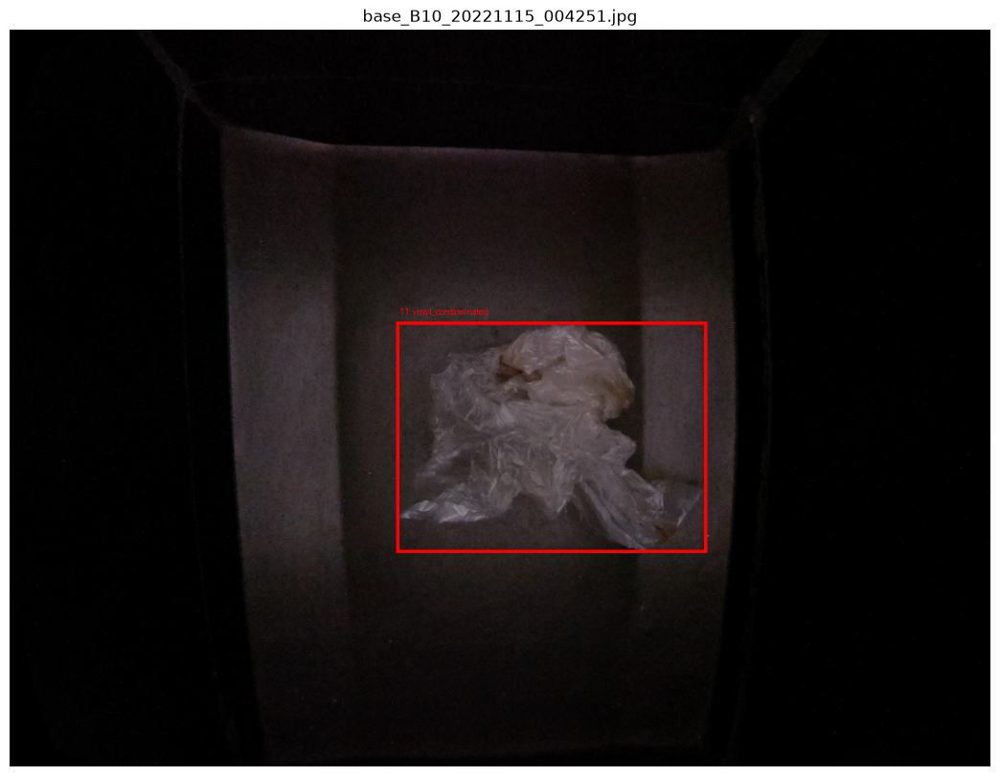

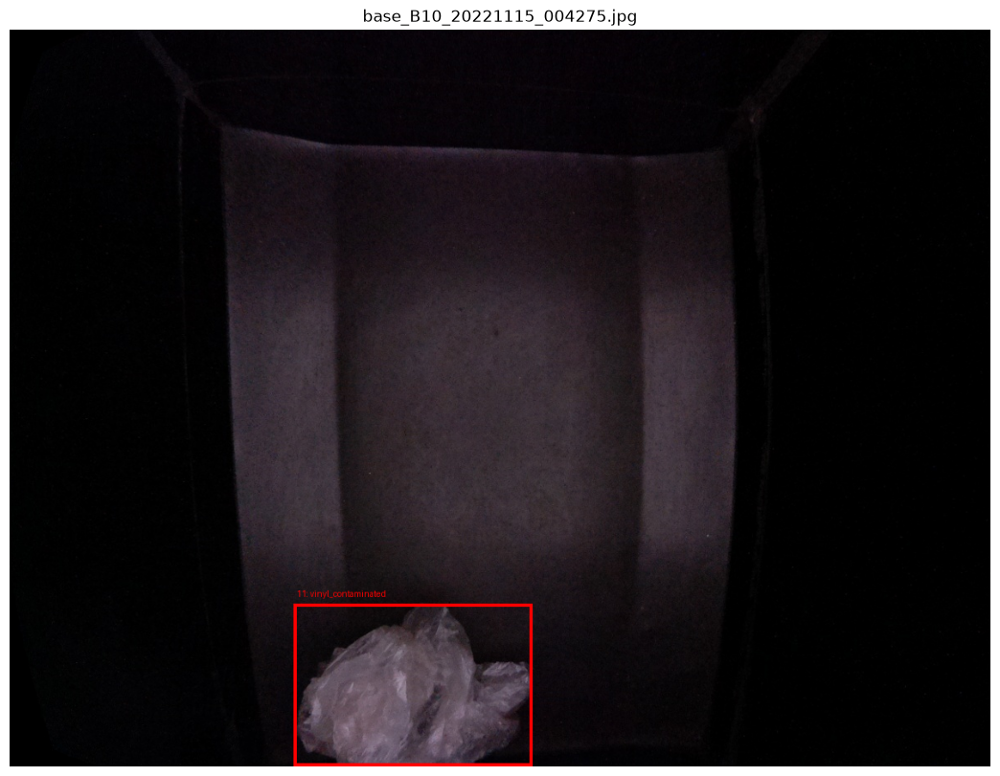

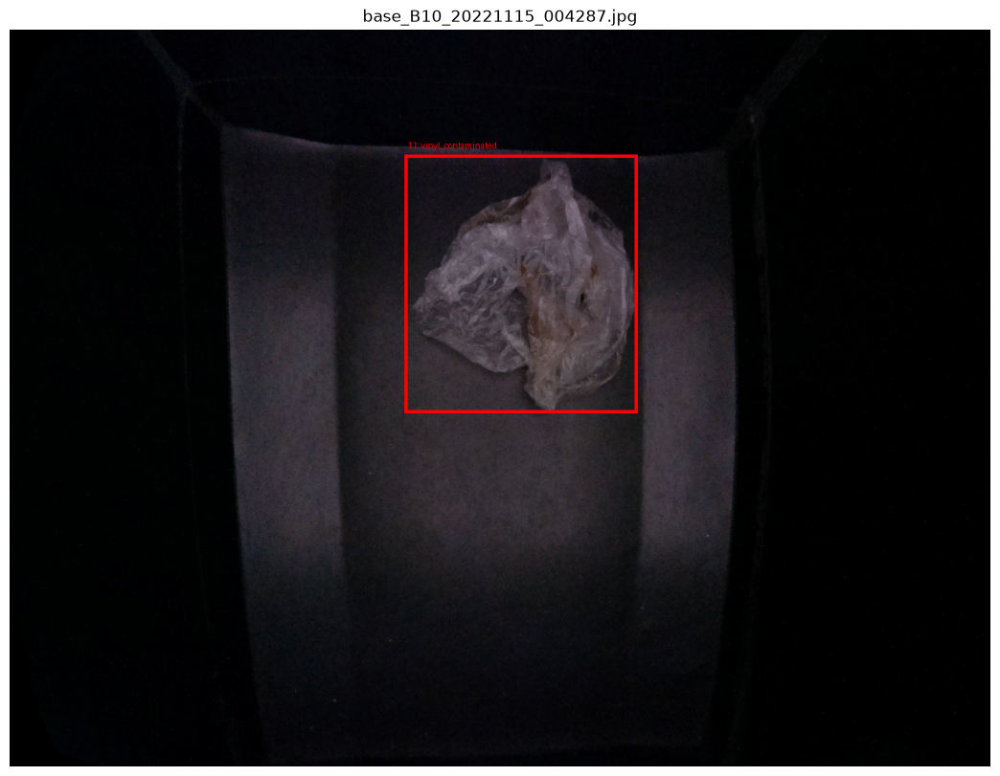

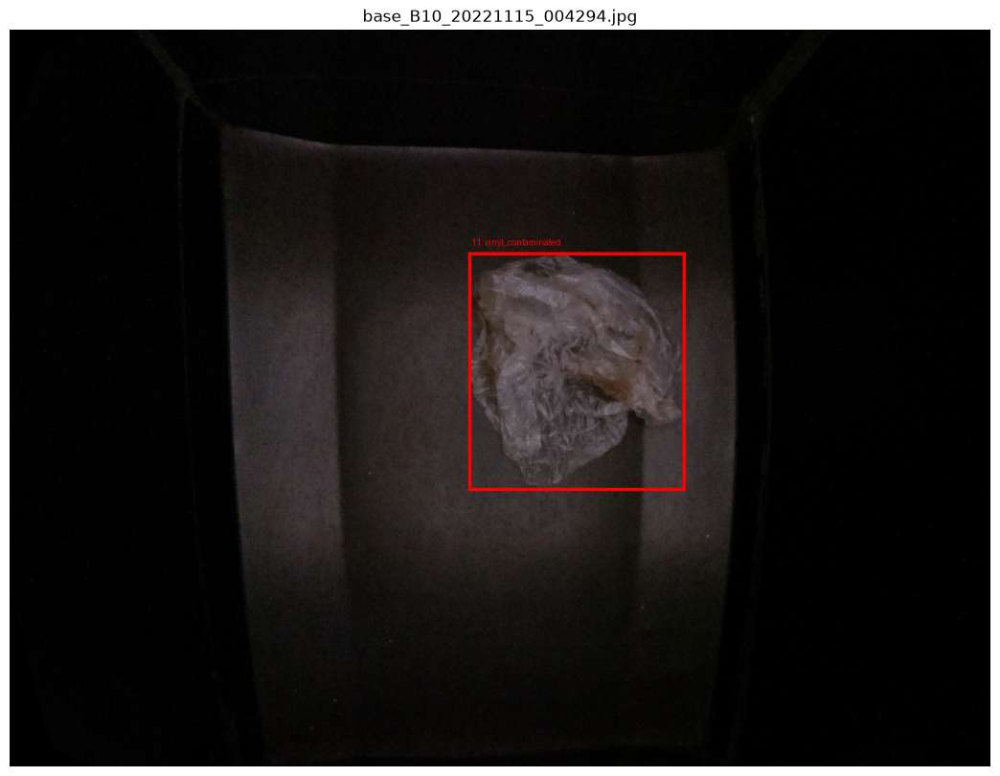

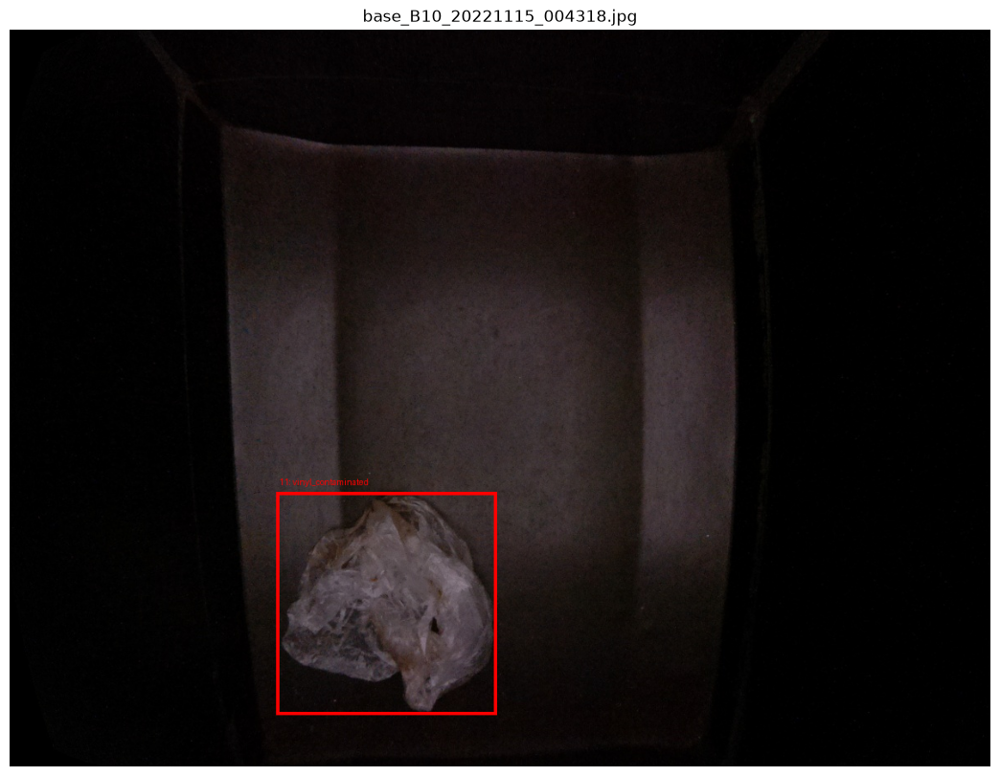

...

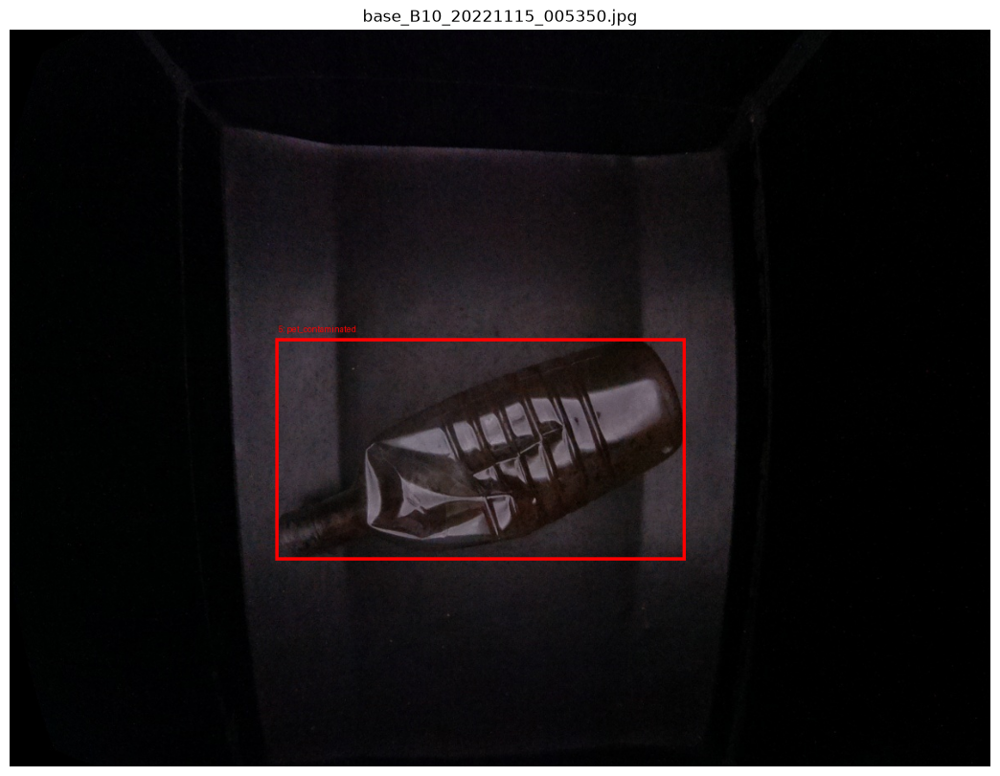

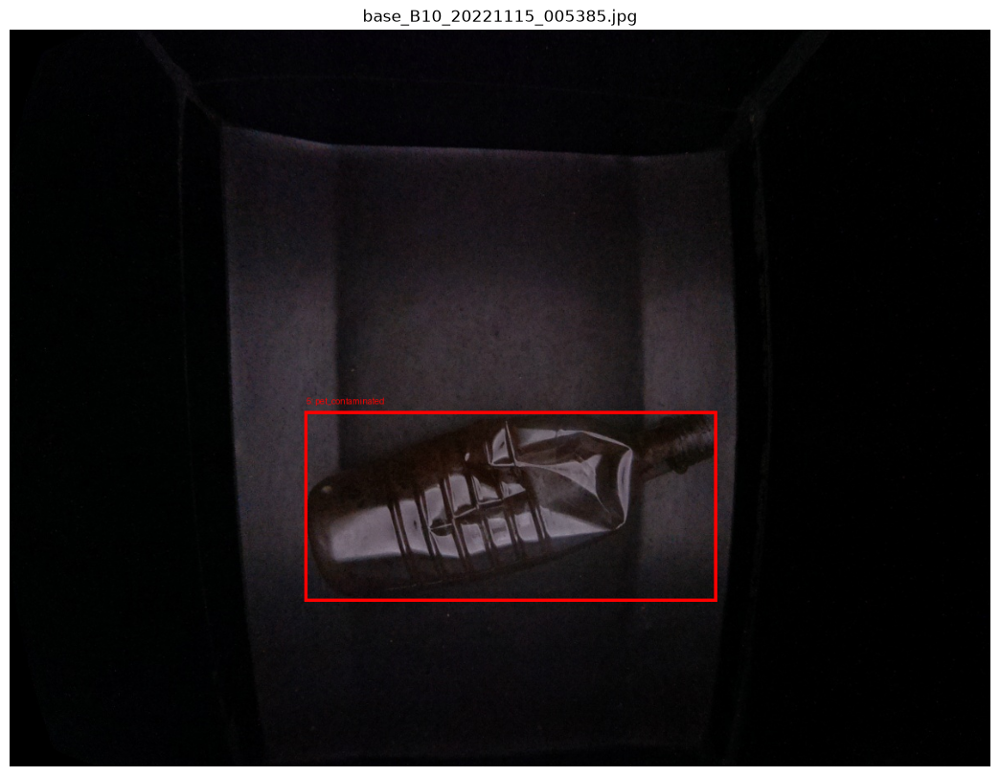

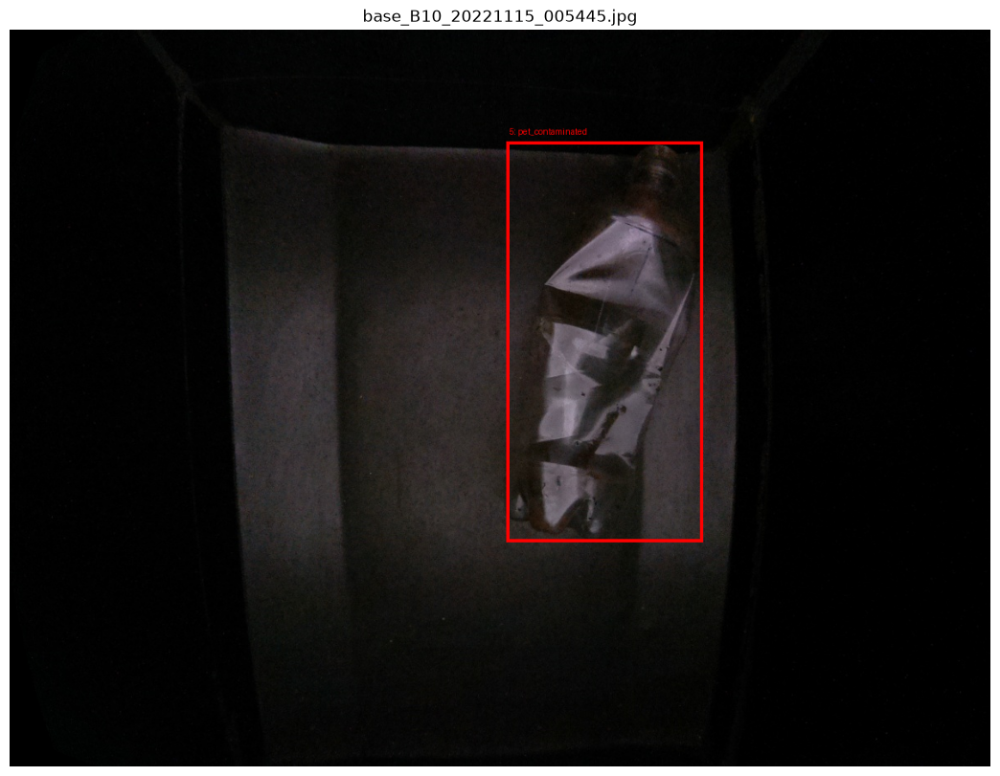

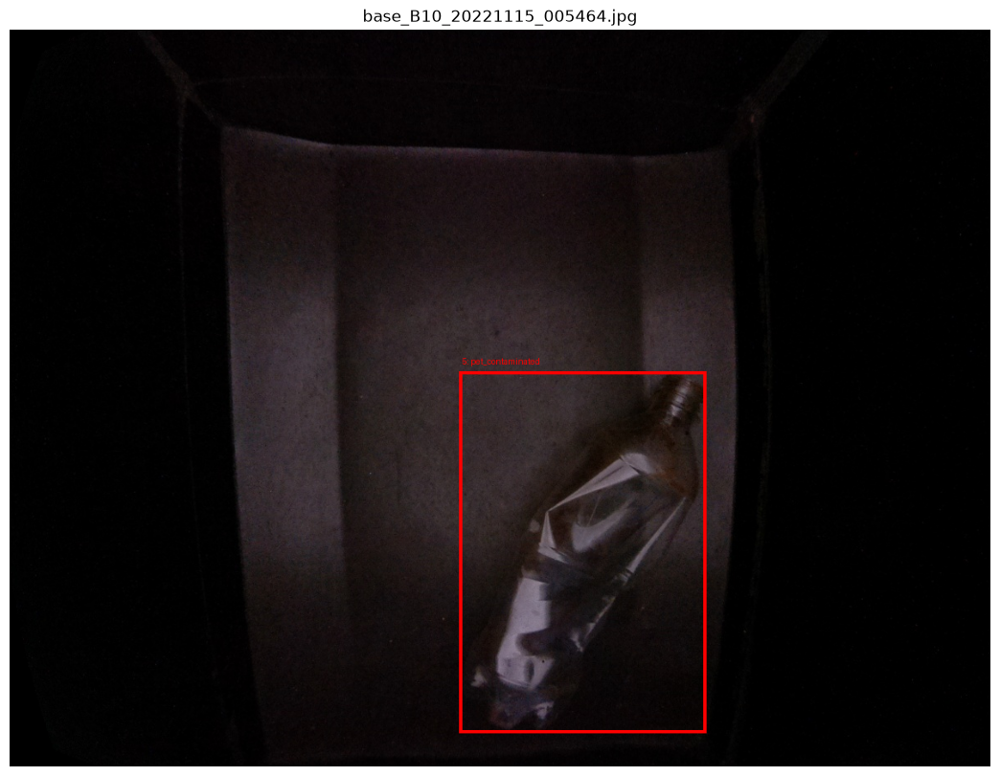

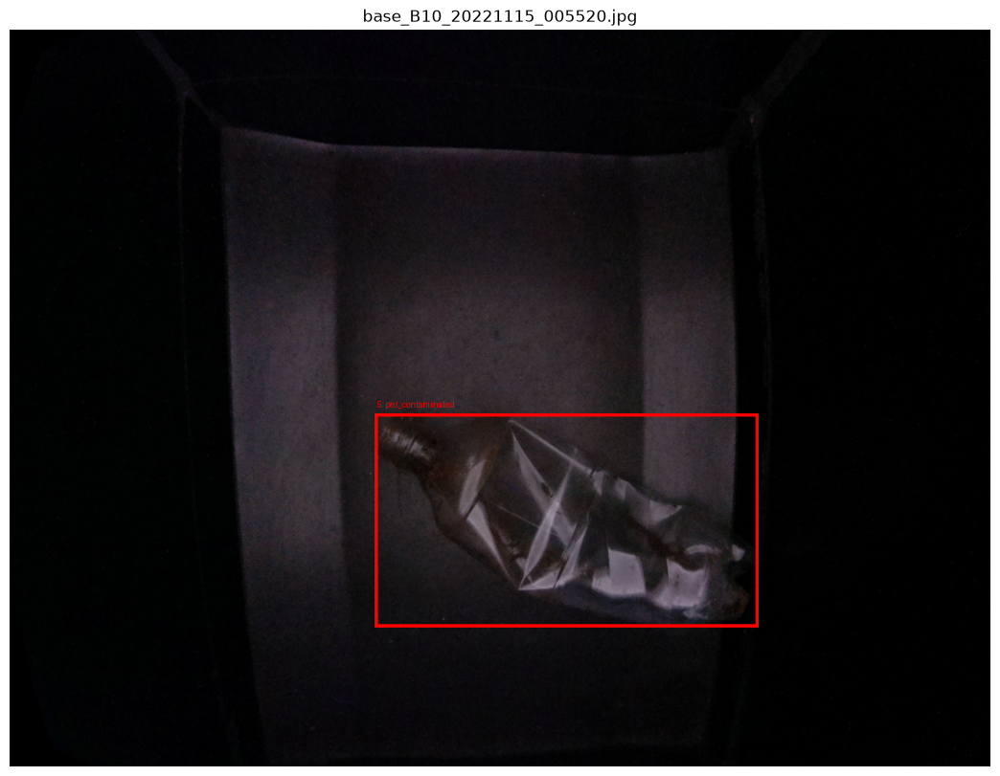

In [10]:
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

root = Path("/data/recycle_dataset/model_a_stage1_14class_27500_v1")

class_names = {
    0: "paper_clean",
    1: "paper_contaminated",
    2: "can_clean",
    3: "can_contaminated",
    4: "pet_clean",
    5: "pet_contaminated",
    6: "plastic_clean",
    7: "plastic_contaminated",
    8: "glass_clean",
    9: "glass_contaminated",
    10: "vinyl_clean",
    11: "vinyl_contaminated",
    12: "class_12",
    13: "class_13",
}

split = "val"

img_dir = root / "images" / split
label_dir = root / "labels" / split

images = sorted(
    p for p in img_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
)

print("이미지 수:", len(images))

for img_path in images[:30]:
    label_path = label_dir / f"{img_path.stem}.txt"

    img = Image.open(img_path).convert("RGB")
    draw = ImageDraw.Draw(img)

    w, h = img.size

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()

            cls = int(parts[0])
            xc, yc, bw, bh = map(float, parts[1:5])

            x1 = (xc - bw / 2) * w
            y1 = (yc - bh / 2) * h
            x2 = (xc + bw / 2) * w
            y2 = (yc + bh / 2) * h

            draw.rectangle(
                [x1, y1, x2, y2],
                outline="red",
                width=4
            )

            name = class_names.get(cls, f"class_{cls}")

            draw.text(
                (x1 + 3, max(0, y1 - 18)),
                f"{cls}: {name}",
                fill="red"
            )

    plt.figure(figsize=(14, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.title(img_path.name)
    plt.show()

In [7]:
tree -L 3 /data/recycle_dataset/model_a_stage1_14class_27500_v1

SyntaxError: invalid syntax (1311505004.py, line 1)

In [8]:
from pathlib import Path

root = Path("/data/recycle_dataset/model_a_stage1_14class_27500_v1")

for p in sorted(root.rglob("*")):
    if p.is_dir():
        print(p)

/data/recycle_dataset/model_a_stage1_14class_27500_v1/images
/data/recycle_dataset/model_a_stage1_14class_27500_v1/images/train
/data/recycle_dataset/model_a_stage1_14class_27500_v1/images/val
/data/recycle_dataset/model_a_stage1_14class_27500_v1/labels
/data/recycle_dataset/model_a_stage1_14class_27500_v1/labels/train
/data/recycle_dataset/model_a_stage1_14class_27500_v1/labels/val
/data/recycle_dataset/model_a_stage1_14class_27500_v1/qa_preview


In [11]:
from ultralytics import YOLO
import yaml

MODEL_PATH = "/data/yolo_runs/recycle_yolo11n/weights/best.pt"
DATA_PATH = "/data/recycle_dataset/model_a_stage1_14class_27500_v1/data.yaml"

model = YOLO(MODEL_PATH)

print("현재 모델 클래스:")
print(model.names)

with open(DATA_PATH, "r", encoding="utf-8") as f:
    data = yaml.safe_load(f)

print("\n새 데이터 클래스:")
print(data["names"])

현재 모델 클래스:
{0: 'paper_clean', 1: 'paper_contaminated', 2: 'can_clean', 3: 'can_contaminated', 4: 'pet_clean', 5: 'pet_contaminated', 6: 'glass_clean', 7: 'glass_contaminated', 8: 'plastic_clean', 9: 'plastic_contaminated', 10: 'vinyl_clean', 11: 'vinyl_contaminated'}

새 데이터 클래스:
{0: 'paper_clean', 1: 'paper_contaminated', 2: 'can_clean', 3: 'can_contaminated', 4: 'pet_clean', 5: 'pet_contaminated', 6: 'glass_clean', 7: 'glass_contaminated', 8: 'plastic_clean', 9: 'plastic_contaminated', 10: 'vinyl_clean', 11: 'vinyl_contaminated', 12: 'styrofoam_clean', 13: 'styrofoam_contaminated'}


In [13]:
pwd

'/data/recycle_dataset/notebooks/model A'

In [3]:
from pathlib import Path

runs = Path("/data/recycle_dataset/notebooks/model A/runs")
a1_pt = runs / "recycle_yolo11n_14class_v1/weights/best.pt"
a2_pt = runs / "recycle_yolo11n_14class_A-2/weights/best.pt"
print("A-1:", a1_pt.is_file(), a1_pt)
print("A-2:", a2_pt.is_file(), a2_pt)

A-1: True /data/recycle_dataset/notebooks/model A/runs/recycle_yolo11n_14class_v1/weights/best.pt
A-2: True /data/recycle_dataset/notebooks/model A/runs/recycle_yolo11n_14class_A-2/weights/best.pt


In [4]:
from pathlib import Path
from ultralytics import YOLO

runs = Path("/data/recycle_dataset/notebooks/model A/runs")
data_yaml = Path("/data/recycle_dataset/model_a_stage1_14class_27500_v1/data.yaml")

models = {
    "A-1": runs / "recycle_yolo11n_14class_v1/weights/best.pt",
    "A-2": runs / "recycle_yolo11n_14class_A-2/weights/best.pt",
}

if not data_yaml.is_file():
    raise FileNotFoundError(data_yaml)

scores = {}

for name, weights in models.items():
    if not weights.is_file():
        raise FileNotFoundError(weights)

    print(f"\n===== {name} 평가 =====")
    result = YOLO(str(weights)).val(
        data=str(data_yaml),
        split="val",
        imgsz=640,
        batch=64,
        device=0,
        verbose=True,
        plots=True,
        project=str(runs / "comparison_A1_A2"),
        name=name,
        exist_ok=False,
    )
    scores[name] = result.results_dict

print("\n===== A-1 / A-2 전체 지표 =====")
for key in (
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)",
):
    print(f"{key}: A-1={scores['A-1'][key]:.4f} | A-2={scores['A-2'][key]:.4f}")


===== A-1 평가 =====
Ultralytics 8.4.154 🚀 Python-3.12.3 torch-2.13.0+cu126 CUDA:0 (Tesla V100-SXM2-32GB, 32494MiB)
YOLO11n summary (fused): 100 layers, 2,584,882 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2155.5±804.6 MB/s, size: 622.0 KB)
val: Scanning /data/recycle_dataset/model_a_stage1_14class_27500_v1/labels/val.cache... 3854 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3854/3854 598.7Mit/s 0.0s
val: /data/recycle_dataset/model_a_stage1_14class_27500_v1/images/val/sty_styro_03331_application_C_20221026_001387.jpg: corrupt JPEG restored and saved
val: /data/recycle_dataset/model_a_stage1_14class_27500_v1/images/val/sty_styro_03361_application_C_20221026_001606.jpg: corrupt JPEG restored and saved
val: /data/recycle_dataset/model_a_stage1_14class_27500_v1/images/val/sty_styro_04371_application_C_20221026_011105.jpg: corrupt JPEG restored and saved
val: /data/recycle_dataset/model_a_stage1_14class_27500_v1/images/val/sty_styro_04421_a

In [5]:
from pathlib import Path
import numpy as np
from ultralytics import YOLO

runs = Path("/data/recycle_dataset/notebooks/model A/runs")
data_yaml = "/data/recycle_dataset/model_a_stage1_14class_27500_v1/data.yaml"

weights = {
    "A-1": runs / "recycle_yolo11n_14class_v1/weights/best.pt",
    "A-2": runs / "recycle_yolo11n_14class_A-2/weights/best.pt",
}

# 현재 14개 클래스: 짝수 ID=clean, 홀수 ID=contaminated
clean_ids = [0, 2, 4, 6, 8, 10, 12]
dirty_ids = [1, 3, 5, 7, 9, 11, 13]

for model_name, pt in weights.items():
    result = YOLO(str(pt)).val(
        data=data_yaml,
        split="val",
        imgsz=640,
        batch=64,
        device=0,
        conf=0.25,          # 두 모델에 동일하게 적용하는 비교 기준
        plots=True,
        verbose=False,
        project=str(runs / "comparison_dirty_to_clean"),
        name=model_name,
        exist_ok=False,
    )

    # 행=예측 클래스, 열=실제 클래스; 마지막 행/열은 background
    cm = result.confusion_matrix.matrix
    names = result.confusion_matrix.names

    if cm.shape != (15, 15):
        raise ValueError(f"예상과 다른 혼동행렬 크기: {cm.shape}")

    wrong = int(cm[np.ix_(clean_ids, dirty_ids)].sum())
    total_dirty = int(cm[:, dirty_ids].sum())

    print(f"\n{model_name}: 오염→clean {wrong}건 / 실제 오염 객체 {total_dirty}개 "
          f"({wrong / total_dirty:.2%})")

    for dirty_id in dirty_ids:
        n = int(cm[clean_ids, dirty_id].sum())
        total = int(cm[:, dirty_id].sum())
        print(f"  {names[dirty_id]}: {n}/{total} ({n / total:.2%})")

Ultralytics 8.4.154 🚀 Python-3.12.3 torch-2.13.0+cu126 CUDA:0 (Tesla V100-SXM2-32GB, 32494MiB)
YOLO11n summary (fused): 100 layers, 2,584,882 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2168.7±690.3 MB/s, size: 757.6 KB)
val: Scanning /data/recycle_dataset/model_a_stage1_14class_27500_v1/labels/val.cache... 3854 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3854/3854 1.6Git/s 0.0s
val: /data/recycle_dataset/model_a_stage1_14class_27500_v1/images/val/sty_styro_03331_application_C_20221026_001387.jpg: corrupt JPEG restored and saved
val: /data/recycle_dataset/model_a_stage1_14class_27500_v1/images/val/sty_styro_03361_application_C_20221026_001606.jpg: corrupt JPEG restored and saved
val: /data/recycle_dataset/model_a_stage1_14class_27500_v1/images/val/sty_styro_04371_application_C_20221026_011105.jpg: corrupt JPEG restored and saved
val: /data/recycle_dataset/model_a_stage1_14class_27500_v1/images/val/sty_styro_04421_application_C_20221026_